In [71]:
import numpy as np
import pandas as pd

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown

sys.path.append(str(Path.cwd().parent))
from src.models.predict_model import load_finalist_model, load_test_data,load_predicted_value,get_threshold_result
from src.visualization.visualize import plot_confusion_matrix,plot_eval_comparison_chart, plot_pre_recall_curve

sys.path.append('..')

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. Load Finalist Trained Models

In [29]:
loaded_models = load_finalist_model()
loaded_models

✅ Success: Model found at D:\All Practice Projects\Git Hub Projects\Machine-Failure-Prediction\models
Loaded: LightGBM_pipeline.pkl
Loaded: XGBoost_pipeline.pkl
Total models loaded: 2
✅ 2 model(s) successfully loaded.


{'LightGBM_pipeline': Pipeline(steps=[('preprocess',
                  ColumnTransformer(transformers=[('num', StandardScaler(),
                                                   ['Air temperature [K]',
                                                    'Process temperature [K]',
                                                    'Rotational speed [rpm]',
                                                    'Torque [Nm]',
                                                    'Tool wear [min]']),
                                                  ('cat',
                                                   OneHotEncoder(handle_unknown='ignore',
                                                                 sparse_output=False),
                                                   ['Type'])])),
                 ('classifier',
                  LGBMClassifier(max_depth=5, n_estimators=200,
                                 objective='binary', random_state=42,
                                 

# 2. Load Test Data

In [7]:
data = load_test_data()
list(data.keys())

test data successfully loaded.


['X_test', 'X_train', 'y_test', 'y_train']

# 3. Load Predicted Data

In [14]:
p_data = load_predicted_value()
list(p_data.keys())

✅ Success: Predicted data found at D:\All Practice Projects\Git Hub Projects\Machine-Failure-Prediction\data\predict
Loaded: LGBMClassifier_predicted_prob.csv
Loaded: XGBClassifier_predicted_prob.csv
Total predicted data files loaded: 2
✅ 2 predicted data files successfully loaded.


['LGBMClassifier_predicted_prob', 'XGBClassifier_predicted_prob']

In [18]:
y_prob_xgb = pd.DataFrame(p_data['XGBClassifier_predicted_prob'])
y_prob_lgb = pd.DataFrame(p_data['LGBMClassifier_predicted_prob'])

# 4. Evaluation By Business Requirement
Let's assume business team want us to identify whether machine is going to fail at least 70% of the time since it starts to operate, I planned to use **recall** as the primary evaluation metric. 
To achieve this, the probability threshold was adjusted to ensure **recall ≥ 0.70**, and **precision** was used as a secondary metric to reduce false positives.

In [23]:
# Finding threshold that achieves Recall >= 0.70
predefined_threshold = 0.70

## 4.1 Evaluate By XGBClassifier

In [ ]:
# get threshold result
result_xgb = get_threshold_result(y_test= data['y_test'], y_proba=y_prob_xgb,threshold=predefined_threshold)
result_xgb

Best threshold for Recall >= 0.7: 0.010
Recall at this threshold: 0.765
Precision at this threshold: 0.776
Confusion Matrix:
[[1917   15]
 [  16   52]]
Classification Report:
              precision    recall  f1-score   support

           0      0.992     0.992     0.992      1932
           1      0.776     0.765     0.770        68

    accuracy                          0.985      2000
   macro avg      0.884     0.878     0.881      2000
weighted avg      0.984     0.985     0.984      2000



{'best_recall': 0.7647058823529411,
 'best_precision': 0.7761194029850746,
 'confusion_matrix': array([[1917,   15],
        [  16,   52]]),
 'confusion_matrix_display': <sklearn.metrics._plot.confusion_matrix.ConfusionMatrixDisplay at 0x1e562e37a10>}

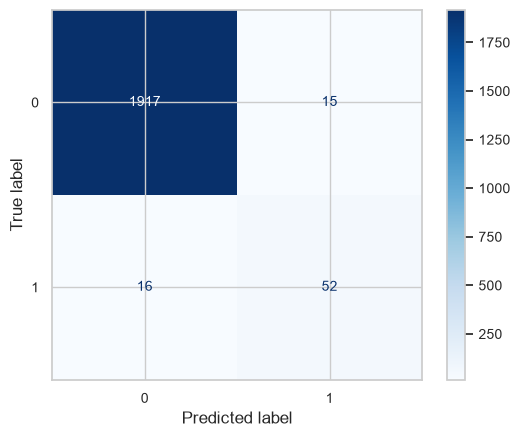

In [67]:
# plot confusion matrix
model_xgb = loaded_models['XGBoost_pipeline'].named_steps['classifier'].__class__.__name__

plot_confusion_matrix(confusion_matrix = result_xgb['confusion_matrix_display'],
                        model_name= model_xgb)


## 4.2 Evaluate By LightGBM

In [65]:
# get threshold result
result_lgb = get_threshold_result(y_test= data['y_test'],
                               y_proba=y_prob_lgb,
                               threshold=predefined_threshold)
result_lgb

Best threshold for Recall >= 0.7: 0.010
Recall at this threshold: 0.809
Precision at this threshold: 0.671
Confusion Matrix:
[[1905   27]
 [  13   55]]
Classification Report:
              precision    recall  f1-score   support

           0      0.993     0.986     0.990      1932
           1      0.671     0.809     0.733        68

    accuracy                          0.980      2000
   macro avg      0.832     0.897     0.861      2000
weighted avg      0.982     0.980     0.981      2000



{'best_recall': 0.8088235294117647,
 'best_precision': 0.6707317073170732,
 'confusion_matrix': array([[1905,   27],
        [  13,   55]]),
 'confusion_matrix_display': <sklearn.metrics._plot.confusion_matrix.ConfusionMatrixDisplay at 0x1e562e35ef0>}

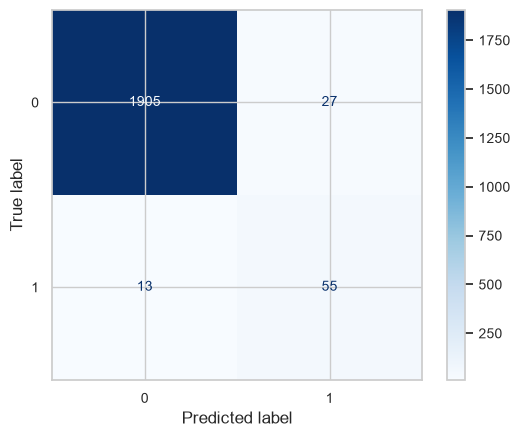

In [68]:
# plot confusion matrix
model_lgb = loaded_models['LightGBM_pipeline'].named_steps['classifier'].__class__.__name__

plot_confusion_matrix(confusion_matrix = result_lgb['confusion_matrix_display'],
                    model_name= model_lgb)

# 5. Result
To compare the results from three different models for both metrics, I decided to create a line plot with a threshold level of 0.7, which aligns with the business requirements.

From the chart below, the XGBoost Classifier performs very well in both metrics compared with the other two classifiers, offering a stronger balance between recall and precision.

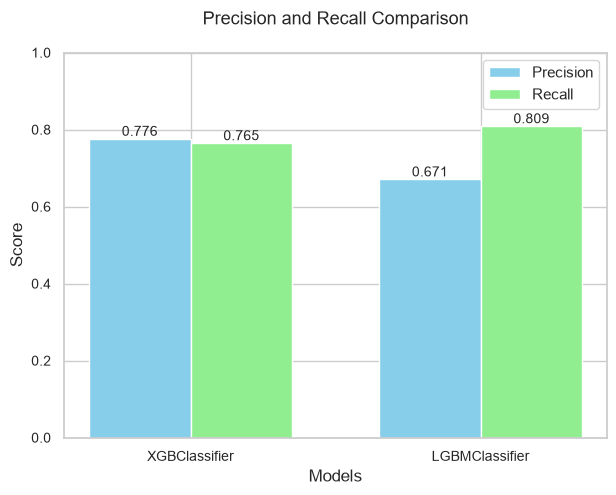

In [70]:
models = [model_xgb, model_lgb]
precision = [result_xgb['best_precision'], result_lgb['best_precision']]
recall = [result_xgb['best_recall'], result_lgb['best_recall']]

plot_eval_comparison_chart(model_list=models,
                           precision_list= precision,
                           recall_list= recall)

d:\All Practice Projects\Git Hub Projects\Machine-Failure-Prediction\.venv\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
d:\All Practice Projects\Git Hub Projects\Machine-Failure-Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
d:\All Practice Projects\Git Hub Projects\Machine-Failure-Prediction\.venv\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


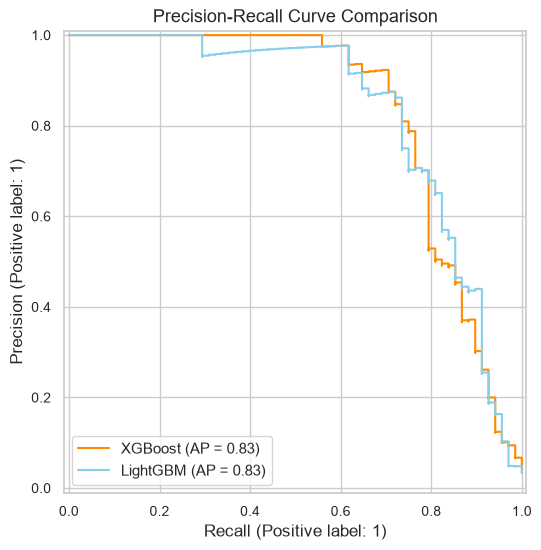

In [72]:
# plot precision and recall curve
plot_pre_recall_curve(pipeline_xgb= loaded_models['XGBoost_pipeline'], 
                      pipeline_lgb= loaded_models['LightGBM_pipeline'],
                      X_test= data['X_test'],
                      y_test= data['y_test'])

# 6. Conclusion
As this AI4I 2020 Predictive Maintenance Dataset notes that it is not transparent to the machine learning model which failure mode caused the machine to fail, **binary classification** is the cleanest starting point. We can then train separate models for each failure type if needed.

For future work, based on the engineering logic described in the data repository, it may be valuable to estimate the failure probabilities associated with the process parameters (TWF, HDF, PWF, OSF, and RNF) in order to better identify the root causes of machine failure.

In the next section, I will develop a separate notebook dedicated to failure-mode-specific models.

# 7. Deployment
We may deploy this model in a production environment using a batch scoring job to continuously monitor machine failure risks. The system can generate periodic predictions based on incoming operational data and track failure patterns across different factory shift types.

In addition, dashboards can be developed to visualize machine health, failure trends, and high-risk operating conditions for maintenance teams and plant managers.

Automated email alerts or notifications could also be triggered when the predicted failure probability exceeds a predefined threshold, enabling proactive maintenance and reducing unexpected downtime.